# Stage 1 results (RQ0)

Numeric accuracy, fabrication rate, distinct answers and answer length per decoding setting (README §8, step A6). Run after A3 and A4; settings without answers or labels yet are skipped.

The numbers come from `analysis/stage1.py` (definitions at the top of that file). What they mean is ours to write (README §3).

In [1]:
import sys
from pathlib import Path

# Find the repo root, whether the notebook runs from the root or from analysis/.
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("run this notebook inside the repo")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display

from common.io import load_config, run_dir
from analysis.stage1 import build_table, write_outputs

# Another model: point CONFIG at its file, e.g. ROOT / "configs" / "llama1b.yaml" (MANUAL_STEPS.md,
# "Other models"); the folders below then become gen/<run_name>/, labels/<run_name>/, ...
CONFIG = ROOT / "config.yaml"
cfg = load_config(CONFIG)
DIR = {f: run_dir(cfg, ROOT, f) for f in ["gen", "labels", "baseline", "features", "detector", "analysis/figures"]}

In [2]:
rows, info = build_table(cfg, ROOT / "data" / "finqa_subset.jsonl", DIR["gen"], DIR["labels"],
                         seed=cfg["seed"])
write_outputs(rows, info, DIR["analysis/figures"])
info

{'settings': ['greedy', 'beam5'],
 'missing_answers': ['temp07', 'temp12', 'topp09'],
 'missing_labels': [],
 'common_questions': 1000,
 'mean_distinct_finals': 1.342}

## Table

All measures, one row per setting (also saved as `analysis/figures/stage1_table.csv`).

In [3]:
pd.DataFrame(rows).set_index("setting").round(3)

,questions,accuracy,accuracy_ci_low,accuracy_ci_high,gold_anywhere,numbers,fabricated_share,fabricated_ci_low,fabricated_ci_high,answers_with_fabricated,copied_share,computed_share,question_share,constant_share,wrong_calc_share,numbers_per_answer,differs_from_greedy,mean_new_tokens,cut_at_max
setting,,,,,,,,,,,,,,,,,,,
greedy,1000,0.486,0.454,0.518,0.518,10306,0.161,0.141,0.179,0.439,0.495,0.120,0.006,0.186,0.032,10.306,0.000,225.774,0.015
beam5,1000,0.503,0.472,0.535,0.526,10448,0.161,0.141,0.180,0.419,0.477,0.123,0.006,0.206,0.028,10.448,0.342,235.551,0.024


In [4]:
display(Markdown((DIR["analysis/figures"] / "stage1_table.md").read_text()))

Questions answered in every setting: 1000. 95% CIs: bootstrap over reports.

| Setting | Accuracy | 95% CI | Fabricated numbers | 95% CI | Answers with a fabricated number | Differs from greedy | Mean tokens | Cut at max |
|---|---|---|---|---|---|---|---|---|
| greedy | 48.6% | 45.4–51.8 | 16.1% | 14.1–17.9 | 43.9% | 0.0% | 226 | 1.5% |
| beam5 | 50.3% | 47.2–53.5 | 16.1% | 14.1–18.0 | 41.9% | 34.2% | 236 | 2.4% |


## Bar chart

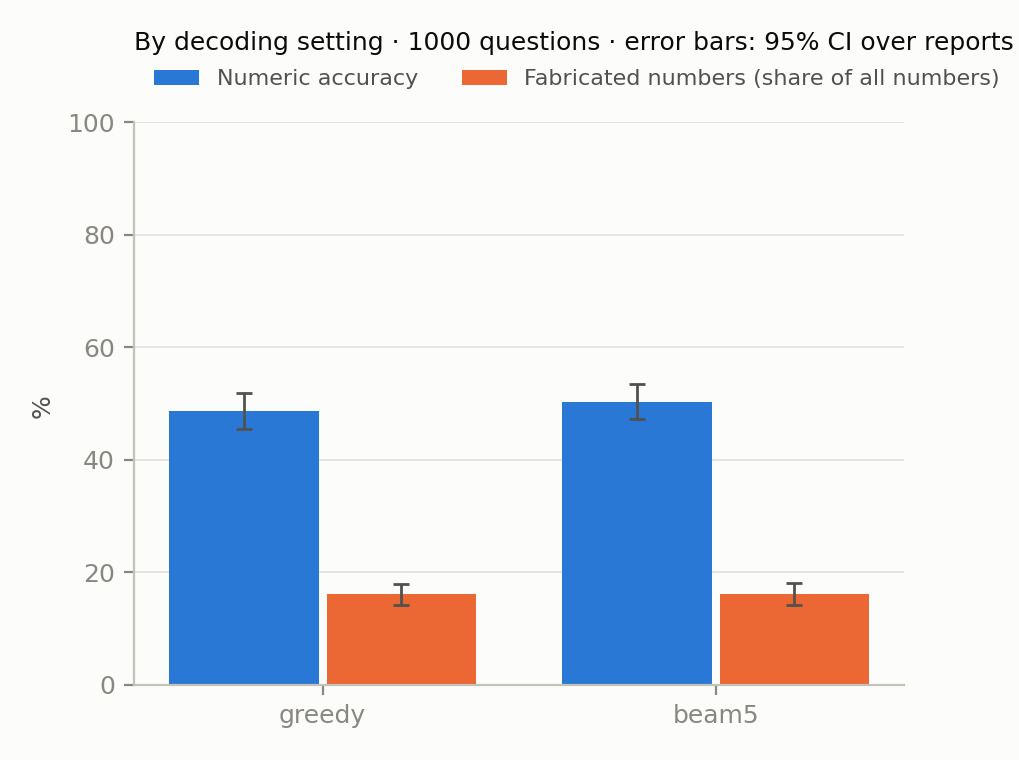

In [5]:
Image(str(DIR["analysis/figures"] / "stage1_bars.png"))

## Our reading

_What we see in the table and chart, and why we think it happens, in our own words (README §3)._